# Predict diabetes subtype classification
Regression of HOMA1-B and HOMA1-IR from insulin to c-peptide values produce slightly different c-peptide estimates.

**Objective:** Evaluate performance of regression on downstream subtype assignment.

# Environment setup
Import required modules.

In [1]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

import joblib

from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score
from sklearn.metrics import classification_report

Load pre-trained random forest model to assign clusters.

In [2]:
rf_path = "/data/user/brianlu/projects/precision_diabetes/cluster_prediction/exports/models/full_linear_rf_model.joblib"

rf = joblib.load(rf_path)

Load test data from HOMA1 regression.

In [3]:
data_path = "../exports/HOMA_regression/cluster_assignment_test_data.csv"

data = pd.read_csv(data_path)

Build label encoder to convert numeric cluster labels into named clusters.

In [4]:
# multiple classes to predict, transform into labels
le = LabelEncoder()
le.fit(np.array(["SAID", "SIDD", "SIRD", "MOD", "MARD"]))
le.classes_ = np.array(["SAID", "SIDD", "SIRD", "MOD", "MARD"])

# Data cleaning
Separate data into c-peptide reference set, insulin baselinse set, and fitted comparison set.

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   DE_ID                      297 non-null    int64  
 1   source                     297 non-null    object 
 2   gender                     166 non-null    object 
 3   race                       166 non-null    object 
 4   glucose                    297 non-null    float64
 5   gad                        297 non-null    int64  
 6   a1c                        297 non-null    float64
 7   bmi                        297 non-null    float64
 8   diabetes_age               297 non-null    float64
 9   homa1_cpeptide_b           297 non-null    float64
 10  homa1_cpeptide_ir          297 non-null    float64
 11  homa1_insulin_b            297 non-null    float64
 12  homa1_insulin_ir           297 non-null    float64
 13  homa1_pred_b               297 non-null    float64

In [6]:
# HOMA1 from measured c-peptide as reference
data_cpeptide = data[["gad", "a1c", "bmi", "diabetes_age", "homa1_cpeptide_b", "homa1_cpeptide_ir"]]

Derive c-peptide from regression.

In [7]:
data["cpeptide_b"] = (data["homa1_pred_b"] * (data["glucose"] - 3.5)) / (20*6)
data["cpeptide_ir"] = (22.5 * data["homa1_pred_ir"]) / (6 * data["glucose"])
data["cpeptide_avg"] = data[['cpeptide_b', 'cpeptide_ir']].mean(axis=1)

Recalculate HOMA1 from predicted c-peptide values.

In [8]:
data["b_homa1_cpeptide_b"] = (20 * 6 * data["cpeptide_b"])/(data["glucose"]-3.5)
data["b_homa1_cpeptide_ir"] = (data["glucose"] * 6 * data["cpeptide_b"]) / 22.5

data["ir_homa1_cpeptide_b"] = (20 * 6 * data["cpeptide_ir"])/(data["glucose"]-3.5)
data["ir_homa1_cpeptide_ir"] = (data["glucose"] * 6 * data["cpeptide_ir"]) / 22.5

data["avg_homa1_cpeptide_b"] = (20 * 6 * data["cpeptide_avg"])/(data["glucose"]-3.5)
data["avg_homa1_cpeptide_ir"] = (data["glucose"] * 6 * data["cpeptide_avg"]) / 22.5


Visualize difference between HOMA1 from regressed c-peptide values against measured c-peptide

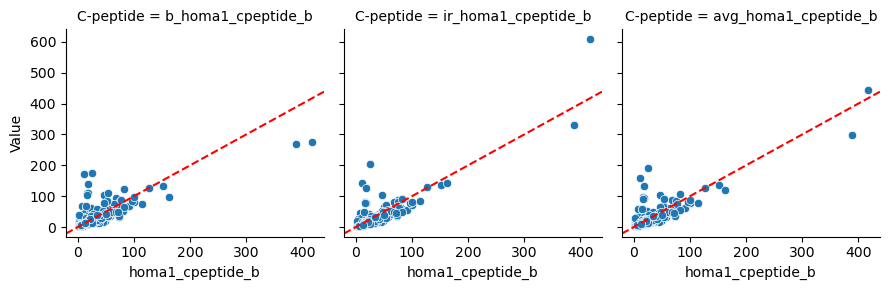

In [9]:
df_long = pd.melt(data, id_vars = ["DE_ID", "homa1_cpeptide_b"], 
                  value_vars = ["b_homa1_cpeptide_b", "ir_homa1_cpeptide_b", "avg_homa1_cpeptide_b"], 
                  var_name = "C-peptide", value_name='Value')

g = sns.FacetGrid(df_long, col = "C-peptide")
g.map(sns.scatterplot, "homa1_cpeptide_b", "Value")

for ax in g.axes.flat:
    ax.axline((0, 0), slope = 1, color = "red", linestyle = "--")
    
plt.show()

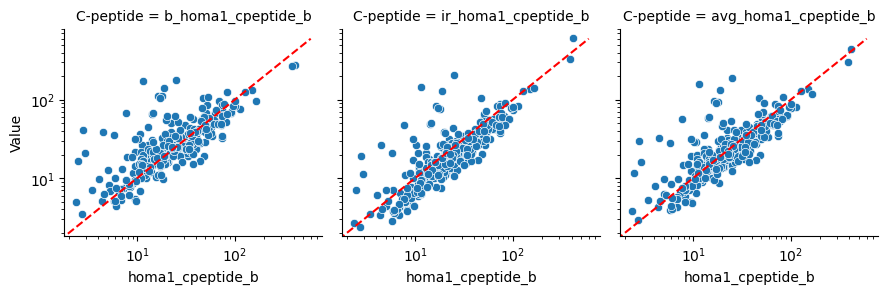

In [10]:
df_long = pd.melt(data, id_vars = ["DE_ID", "homa1_cpeptide_b"], 
                  value_vars = ["b_homa1_cpeptide_b", "ir_homa1_cpeptide_b", "avg_homa1_cpeptide_b"], 
                  var_name = "C-peptide", value_name='Value')

g = sns.FacetGrid(df_long, col = "C-peptide")
g.map(sns.scatterplot, "homa1_cpeptide_b", "Value")

for ax in g.axes.flat:
    ax.plot([0, 600], [0, 600], color = "red", linestyle = "--")
    ax.set_xscale("log")
    ax.set_yscale("log")
    
plt.show()

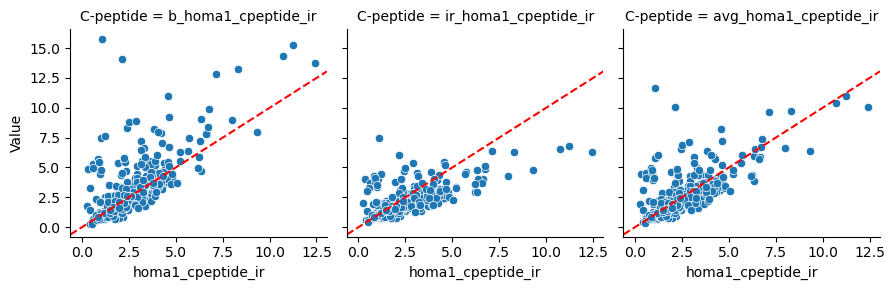

In [11]:
df_long = pd.melt(data, id_vars = ["DE_ID", "homa1_cpeptide_ir"], 
                  value_vars = ["b_homa1_cpeptide_ir", "ir_homa1_cpeptide_ir", "avg_homa1_cpeptide_ir"], 
                  var_name = "C-peptide", value_name='Value')

g = sns.FacetGrid(df_long, col = "C-peptide")
g.map(sns.scatterplot, "homa1_cpeptide_ir", "Value")

for ax in g.axes.flat:
    ax.axline((0, 0), slope = 1, color = "red", linestyle = "--")
    
plt.show()

Visualize difference between HOMA1 from regressed c-peptide values.

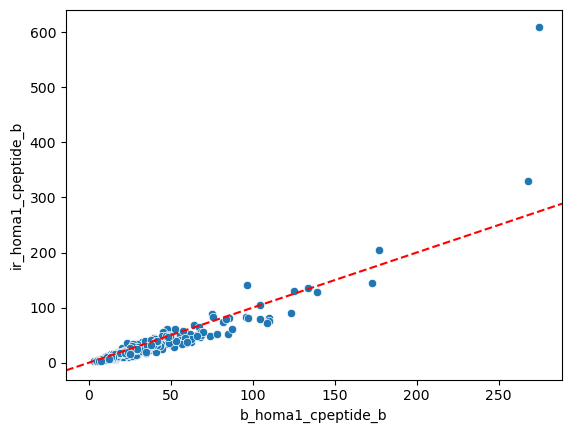

In [12]:
ax = sns.scatterplot(data, x = "b_homa1_cpeptide_b", y = "ir_homa1_cpeptide_b")
ax.axline((0, 0), slope = 1, color = "red", linestyle = "--");

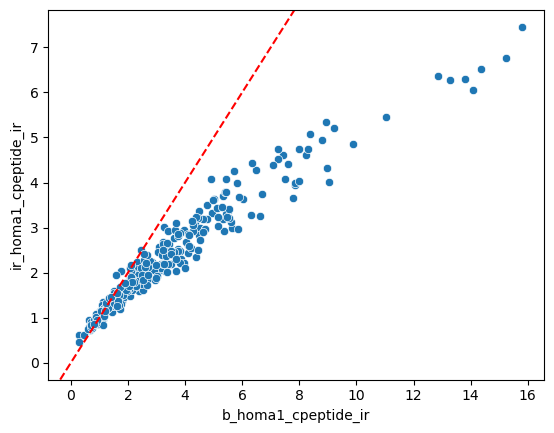

In [13]:
ax = sns.scatterplot(data, x = "b_homa1_cpeptide_ir", y = "ir_homa1_cpeptide_ir")
ax.axline((0, 0), slope = 1, color = "red", linestyle = "--");

Separate data for cluster assignments.

In [14]:
# c-peptide from HOMA1-B regression
data_b = data[["gad", "a1c", "bmi", "diabetes_age", "b_homa1_cpeptide_b", "b_homa1_cpeptide_ir"]]

# direct from regression without back calculating c-peptide
data_regression =  data[["gad", "a1c", "bmi", "diabetes_age", "homa1_pred_b", "homa1_pred_ir"]]

## rename columns to match prediction model
data_regression = data_regression.rename(columns = {"homa1_pred_b" : "homa1_cpeptide_b",
                                                       "homa1_pred_ir" : "homa1_cpeptide_ir"})

## rename columns to match prediction model
data_b = data_b.rename(columns = {"b_homa1_cpeptide_b" : "homa1_cpeptide_b",
                                   "b_homa1_cpeptide_ir" : "homa1_cpeptide_ir"})
# c-peptide from HOMA1-IR regression
data_ir = data[["gad", "a1c", "bmi", "diabetes_age", "ir_homa1_cpeptide_b", "ir_homa1_cpeptide_ir"]]

## rename columns to match prediction model
data_ir = data_ir.rename(columns = {"ir_homa1_cpeptide_b" : "homa1_cpeptide_b",
                                    "ir_homa1_cpeptide_ir" : "homa1_cpeptide_ir"})

# c-peptide from average regression
data_avg = data[["gad", "a1c", "bmi", "diabetes_age", "avg_homa1_cpeptide_b", "avg_homa1_cpeptide_ir"]]

## rename columns to match prediction model
data_avg = data_avg.rename(columns = {"avg_homa1_cpeptide_b" : "homa1_cpeptide_b",
                                    "avg_homa1_cpeptide_ir" : "homa1_cpeptide_ir"})

Separate data with cluster assignments known from [Lu et al](https://doi.org/10.1210/clinem/dgae516) to use the exact same glucose values as during initial clustering.

In [15]:
# UAB records with known clusters from hierarchical clustering
clustered_data = data.dropna(subset = "Ahlqvist").copy()

clustered_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 166 entries, 0 to 165
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   DE_ID                      166 non-null    int64  
 1   source                     166 non-null    object 
 2   gender                     166 non-null    object 
 3   race                       166 non-null    object 
 4   glucose                    166 non-null    float64
 5   gad                        166 non-null    int64  
 6   a1c                        166 non-null    float64
 7   bmi                        166 non-null    float64
 8   diabetes_age               166 non-null    float64
 9   homa1_cpeptide_b           166 non-null    float64
 10  homa1_cpeptide_ir          166 non-null    float64
 11  homa1_insulin_b            166 non-null    float64
 12  homa1_insulin_ir           166 non-null    float64
 13  homa1_pred_b               166 non-null    float64
 14 

Derive c-peptide from regression.

In [16]:
clustered_data["cpeptide_b"] = (clustered_data["cluster_homa1b_pred"] * (clustered_data["homa_cpeptide_glucose"] - 3.5)) / (20*6)
clustered_data["cpeptide_ir"] = (22.5 * clustered_data["cluster_homa1ir_pred"]) / (6 * clustered_data["homa_cpeptide_glucose"])
clustered_data["cpeptide_avg"] = clustered_data[['cpeptide_b', 'cpeptide_ir']].mean(axis=1)

Visualize difference between measured and regressed c-peptide values.

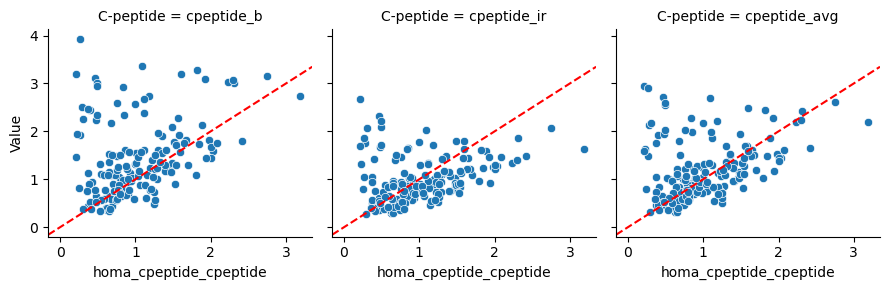

In [17]:
df_long = pd.melt(clustered_data, id_vars = ["DE_ID", "homa_cpeptide_cpeptide"], 
                  value_vars = ["cpeptide_b", "cpeptide_ir", "cpeptide_avg"], 
                  var_name = "C-peptide", value_name='Value')

g = sns.FacetGrid(df_long, col = "C-peptide")
g.map(sns.scatterplot, "homa_cpeptide_cpeptide", "Value")

for ax in g.axes.flat:
    ax.axline((0, 0), slope = 1, color = "red", linestyle = "--")
    
plt.show()

Recalculate HOMA1 from predicted c-peptide values.

In [18]:
clustered_data["b_homa1_cpeptide_b"] = (20 * 6 * clustered_data["cpeptide_b"])/(clustered_data["homa_cpeptide_glucose"]-3.5)
clustered_data["b_homa1_cpeptide_ir"] = (clustered_data["homa_cpeptide_glucose"] * 6 * clustered_data["cpeptide_b"]) / 22.5

clustered_data["ir_homa1_cpeptide_b"] = (20 * 6 * clustered_data["cpeptide_ir"])/(clustered_data["homa_cpeptide_glucose"]-3.5)
clustered_data["ir_homa1_cpeptide_ir"] = (clustered_data["homa_cpeptide_glucose"] * 6 * clustered_data["cpeptide_ir"]) / 22.5

clustered_data["avg_homa1_cpeptide_b"] = (20 * 6 * clustered_data["cpeptide_avg"])/(clustered_data["homa_cpeptide_glucose"]-3.5)
clustered_data["avg_homa1_cpeptide_ir"] = (clustered_data["homa_cpeptide_glucose"] * 6 * clustered_data["cpeptide_avg"]) / 22.5


Separate data for cluster assignments.

In [19]:
# measured c-peptide
clustered_data_cpeptide = clustered_data[["gad", "a1c", "bmi", "diabetes_age", "cluster_homa1_cpeptide_b", "cluster_homa1_cpeptide_ir"]]

## rename columns to match prediction model
clustered_data_cpeptide = clustered_data_cpeptide.rename(columns = {"cluster_homa1_cpeptide_b" : "homa1_cpeptide_b",
                                                       "cluster_homa1_cpeptide_ir" : "homa1_cpeptide_ir"})

# direct from regression without back calculating c-peptide
clustered_data_regression =  clustered_data[["gad", "a1c", "bmi", "diabetes_age", "cluster_homa1b_pred", "cluster_homa1ir_pred"]]

## rename columns to match prediction model
clustered_data_regression = clustered_data_regression.rename(columns = {"cluster_homa1b_pred" : "homa1_cpeptide_b",
                                                       "cluster_homa1ir_pred" : "homa1_cpeptide_ir"})

# c-peptide from HOMA1-B regression
clustered_data_b = clustered_data[["gad", "a1c", "bmi", "diabetes_age", "b_homa1_cpeptide_b", "b_homa1_cpeptide_ir"]]

## rename columns to match prediction model
clustered_data_b = clustered_data_b.rename(columns = {"b_homa1_cpeptide_b" : "homa1_cpeptide_b",
                                                       "b_homa1_cpeptide_ir" : "homa1_cpeptide_ir"})
# c-peptide from HOMA1-IR regression
clustered_data_ir = clustered_data[["gad", "a1c", "bmi", "diabetes_age", "ir_homa1_cpeptide_b", "ir_homa1_cpeptide_ir"]]

# rename columns to match prediction model
clustered_data_ir = clustered_data_ir.rename(columns = {"ir_homa1_cpeptide_b" : "homa1_cpeptide_b",
                                                        "ir_homa1_cpeptide_ir" : "homa1_cpeptide_ir"})

# c-peptide from HOMA1-IR regression
clustered_data_avg = clustered_data[["gad", "a1c", "bmi", "diabetes_age", "avg_homa1_cpeptide_b", "avg_homa1_cpeptide_ir"]]

# rename columns to match prediction model
clustered_data_avg = clustered_data_avg.rename(columns = {"avg_homa1_cpeptide_b" : "homa1_cpeptide_b",
                                                        "avg_homa1_cpeptide_ir" : "homa1_cpeptide_ir"})

# Model evaluation
Use trained model to assign clusters for each dataset.

## Define specificity

In [20]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import confusion_matrix

# set up one-vs-rest labels
label_binarizer = LabelBinarizer().fit(clustered_data["Ahlqvist"])

def binarize_y(y_true_sample, y_pred_sample):
    y_onehot_sample_test = label_binarizer.transform(y_true_sample)
    y_onehot_sample_pred = label_binarizer.transform(y_pred_sample)
    return y_onehot_sample_test, y_onehot_sample_pred

def binary_specificity(y_true_sample, y_pred_sample, axis = -1):
    cm = confusion_matrix(y_true_sample, y_pred_sample, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)
    return specificity

# store metric functions in dicionary to call in function
binary_metrics = {"specificity": binary_specificity}

# define recurring operations as functions
def get_support(y_true_sample, y_pred_sample):
    _, _, _, support = precision_recall_fscore_support(y_true_sample, y_pred_sample, average = None)
    return support

def weighted_average(scores, support):
    return np.sum((scores * support)/np.sum(support))

# extend binary metrics to multiclass
def weighted_metric(y_true_sample, y_pred_sample, metric, axis = -1):
    ''' Extension of binary one-vs-rest per class metrics into multiclass metric.
    
    Calls the specified binary one-vs-rest per class metric and calculates 
    the average weighted by the support for each class, same as how sklearn
    calculates weighted metrics.
    '''
    
    # calculate support
    support = get_support(y_true_sample, y_pred_sample)
    
    # binarize samples
    y_onehot_sample_test, y_onehot_sample_pred = binarize_y(y_true_sample, y_pred_sample)
    
    # empty array to store per class metrics
    onehot_score = np.empty(0)
    
    # calculate per class score
    for class_id in range(y_onehot_sample_test.shape[1]):    
        class_metric = binary_metrics[metric](y_onehot_sample_test[:,class_id], y_onehot_sample_pred[:,class_id])
        onehot_score = np.append(onehot_score, class_metric)
    
    # calculate weighte average
    weighted_score = weighted_average(onehot_score, support)
    
    return weighted_score

def multiclass_specificity(y_true_sample, y_pred_sample, axis = -1):
    return weighted_metric(y_true_sample, y_pred_sample, "specificity", axis = axis)

## Model prediction against prediction by c-peptide

In [21]:
predictors = ["gad", "a1c", "bmi", "diabetes_age", "homa1_cpeptide_b", "homa1_cpeptide_ir"]

# assign cluster based on trained model
mapped_clusters = rf.predict(data_cpeptide[predictors])

# convert encoded labels back to cluster names
mapped_clusters = le.inverse_transform(mapped_clusters)

# insert back into data
data["cpeptide_clusters"] = mapped_clusters

In [22]:
# assign cluster based on trained model
regression_clusters = rf.predict(data_regression[predictors])

# convert encoded labels back to cluster names
regression_clusters = le.inverse_transform(regression_clusters)

# insert back into data
data["regression_clusters"] = regression_clusters

In [23]:
# assign cluster based on trained model
b_clusters = rf.predict(data_b[predictors])

# convert encoded labels back to cluster names
b_clusters = le.inverse_transform(b_clusters)

# insert back into data
data["b_clusters"] = b_clusters

In [24]:
# assign cluster based on trained model
ir_clusters = rf.predict(data_ir[predictors])

# convert encoded labels back to cluster names
ir_clusters = le.inverse_transform(ir_clusters)

# insert back into data
data["ir_clusters"] = ir_clusters

In [25]:
# assign cluster based on trained model
avg_clusters = rf.predict(data_avg[predictors])

# convert encoded labels back to cluster names
avg_clusters = le.inverse_transform(avg_clusters)

# insert back into data
data["avg_clusters"] = avg_clusters

In [26]:
scores = pd.DataFrame({"metric" : ["accuracy", "precision", "recall/sensitivity", "specificity", "F1", "Kappa"],
                       "regression HOMA directly" : [balanced_accuracy_score(data["cpeptide_clusters"], data["regression_clusters"]),
                                         precision_score(data["cpeptide_clusters"], data["regression_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(data["cpeptide_clusters"], data["regression_clusters"], 
                                                                  average = "weighted"),
                                               multiclass_specificity(data["cpeptide_clusters"], data["regression_clusters"]),
                                         f1_score(data["cpeptide_clusters"], data["regression_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(data["cpeptide_clusters"], data["regression_clusters"])],
                       "regression HOMA1-B" : [balanced_accuracy_score(data["cpeptide_clusters"], data["b_clusters"]),
                                         precision_score(data["cpeptide_clusters"], data["b_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(data["cpeptide_clusters"], data["b_clusters"], 
                                                                  average = "weighted"),
                                               multiclass_specificity(data["cpeptide_clusters"], data["b_clusters"]),
                                         f1_score(data["cpeptide_clusters"], data["b_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(data["cpeptide_clusters"], data["b_clusters"])],
                       "regression HOMA1-IR" : [balanced_accuracy_score(data["cpeptide_clusters"], data["ir_clusters"]),
                                         precision_score(data["cpeptide_clusters"], data["ir_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(data["cpeptide_clusters"], data["ir_clusters"], 
                                                                  average = "weighted"),
                                                multiclass_specificity(data["cpeptide_clusters"], data["ir_clusters"]),
                                         f1_score(data["cpeptide_clusters"], data["ir_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(data["cpeptide_clusters"], data["ir_clusters"])],
                     "regression average" : [balanced_accuracy_score(data["cpeptide_clusters"], data["avg_clusters"]),
                                         precision_score(data["cpeptide_clusters"], data["avg_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(data["cpeptide_clusters"], data["avg_clusters"], 
                                                                  average = "weighted"),
                                             multiclass_specificity(data["cpeptide_clusters"], data["avg_clusters"]),
                                         f1_score(data["cpeptide_clusters"], data["avg_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(data["cpeptide_clusters"], data["avg_clusters"])]})

scores

,metric,regression HOMA directly,regression HOMA1-B,regression HOMA1-IR,regression average
0,accuracy,0.897198,0.905852,0.905930,0.910449
1,precision,0.877620,0.889051,0.889738,0.895047
2,recall/sensitivity,0.872054,0.882155,0.888889,0.892256
3,specificity,0.958514,0.962622,0.961308,0.963681
4,F1,0.873350,0.883868,0.887166,0.892055
5,Kappa,0.832830,0.846139,0.854245,0.858878


In [27]:
print(classification_report(data["cpeptide_clusters"], data["regression_clusters"]))

              precision    recall  f1-score   support

        MARD       0.80      0.88      0.84        80
         MOD       0.97      0.86      0.91        84
        SAID       1.00      1.00      1.00        14
        SIDD       0.98      1.00      0.99        54
        SIRD       0.73      0.75      0.74        65

    accuracy                           0.87       297
   macro avg       0.90      0.90      0.90       297
weighted avg       0.88      0.87      0.87       297



In [28]:
print(classification_report(data["cpeptide_clusters"], data["avg_clusters"]))

              precision    recall  f1-score   support

        MARD       0.80      0.91      0.85        80
         MOD       0.97      0.92      0.94        84
        SAID       1.00      1.00      1.00        14
        SIDD       1.00      1.00      1.00        54
        SIRD       0.80      0.72      0.76        65

    accuracy                           0.89       297
   macro avg       0.91      0.91      0.91       297
weighted avg       0.90      0.89      0.89       297



Export scores.

In [29]:
scores.to_csv("../exports/HOMA_regression/fe_scores_against_cpeptide.csv", index = False)

## Model prediction against known clusters

In [30]:
clustered_data = clustered_data.rename(columns = {"Ahlqvist" : "hierarchical"})

In [31]:
# assign cluster based on trained model
mapped_clusters = rf.predict(clustered_data_cpeptide[predictors])

# convert encoded labels back to cluster names
mapped_clusters = le.inverse_transform(mapped_clusters)

# insert back into data
clustered_data["cpeptide_clusters"] = mapped_clusters

In [32]:
# assign cluster based on trained model
mapped_clusters = rf.predict(clustered_data_regression[predictors])

# convert encoded labels back to cluster names
regression_clusters = le.inverse_transform(mapped_clusters)

# insert back into data
clustered_data["regression_clusters"] = regression_clusters

In [33]:
# assign cluster based on trained model
mapped_clusters = rf.predict(clustered_data_b[predictors])

# convert encoded labels back to cluster names
mapped_clusters = le.inverse_transform(mapped_clusters)

# insert back into data
clustered_data["b_clusters"] = mapped_clusters

In [34]:
# assign cluster based on trained model
mapped_clusters = rf.predict(clustered_data_ir[predictors])

# convert encoded labels back to cluster names
mapped_clusters = le.inverse_transform(mapped_clusters)

# insert back into data
clustered_data["ir_clusters"] = mapped_clusters

In [35]:
# assign cluster based on trained model
mapped_clusters = rf.predict(clustered_data_avg[predictors])

# convert encoded labels back to cluster names
mapped_clusters = le.inverse_transform(mapped_clusters)

# insert back into data
clustered_data["avg_clusters"] = mapped_clusters

In [36]:
scores = pd.DataFrame({"metric" : ["accuracy", "precision", "recall/sensitivity", "specificity", "F1", "Kappa"],
                       "regression HOMA directly" : [balanced_accuracy_score(clustered_data["hierarchical"], clustered_data["regression_clusters"]),
                                         precision_score(clustered_data["hierarchical"], clustered_data["regression_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(clustered_data["hierarchical"], clustered_data["regression_clusters"], 
                                                                  average = "weighted"),
                                               multiclass_specificity(clustered_data["hierarchical"], clustered_data["regression_clusters"]),
                                         f1_score(clustered_data["hierarchical"], clustered_data["regression_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(clustered_data["hierarchical"], clustered_data["regression_clusters"])],
                       "regression HOMA1-B" : [balanced_accuracy_score(clustered_data["hierarchical"], clustered_data["b_clusters"]),
                                         precision_score(clustered_data["hierarchical"], clustered_data["b_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(clustered_data["hierarchical"], clustered_data["b_clusters"], 
                                                                  average = "weighted"),
                                               multiclass_specificity(clustered_data["hierarchical"], clustered_data["b_clusters"]),
                                         f1_score(clustered_data["hierarchical"], clustered_data["b_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(clustered_data["hierarchical"], clustered_data["b_clusters"])],
                       "regression HOMA1-IR" : [balanced_accuracy_score(clustered_data["hierarchical"], clustered_data["ir_clusters"]),
                                         precision_score(clustered_data["hierarchical"], clustered_data["ir_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(clustered_data["hierarchical"], clustered_data["ir_clusters"], 
                                                                  average = "weighted"),
                                                multiclass_specificity(clustered_data["hierarchical"], clustered_data["ir_clusters"]),
                                         f1_score(clustered_data["hierarchical"], clustered_data["ir_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(clustered_data["hierarchical"], clustered_data["ir_clusters"])],
                     "regression average" : [balanced_accuracy_score(clustered_data["hierarchical"], clustered_data["avg_clusters"]),
                                         precision_score(clustered_data["hierarchical"], clustered_data["avg_clusters"], 
                                                                  average = "weighted"),
                                         recall_score(clustered_data["hierarchical"], clustered_data["avg_clusters"], 
                                                                  average = "weighted"),
                                             multiclass_specificity(clustered_data["hierarchical"], clustered_data["avg_clusters"]),
                                         f1_score(clustered_data["hierarchical"], clustered_data["avg_clusters"], 
                                                                  average = "weighted"),
                                         cohen_kappa_score(clustered_data["hierarchical"], clustered_data["avg_clusters"])]})

scores

,metric,regression HOMA directly,regression HOMA1-B,regression HOMA1-IR,regression average
0,accuracy,0.877595,0.892540,0.890835,0.909703
1,precision,0.897436,0.913305,0.899837,0.925634
2,recall/sensitivity,0.873494,0.885542,0.897590,0.915663
3,specificity,0.974731,0.978841,0.973499,0.984557
4,F1,0.879255,0.891933,0.897610,0.918625
5,Kappa,0.836399,0.852175,0.866275,0.890383


In [37]:
print(classification_report(clustered_data["hierarchical"], clustered_data["cpeptide_clusters"]))

              precision    recall  f1-score   support

        MARD       0.97      1.00      0.98        32
         MOD       1.00      0.98      0.99        51
        SAID       1.00      1.00      1.00        14
        SIDD       1.00      1.00      1.00        46
        SIRD       0.96      0.96      0.96        23

    accuracy                           0.99       166
   macro avg       0.99      0.99      0.99       166
weighted avg       0.99      0.99      0.99       166



In [38]:
print(classification_report(clustered_data["hierarchical"], clustered_data["regression_clusters"]))

              precision    recall  f1-score   support

        MARD       0.85      0.72      0.78        32
         MOD       0.98      0.84      0.91        51
        SAID       1.00      1.00      1.00        14
        SIDD       0.98      1.00      0.99        46
        SIRD       0.56      0.83      0.67        23

    accuracy                           0.87       166
   macro avg       0.87      0.88      0.87       166
weighted avg       0.90      0.87      0.88       166



In [39]:
print(classification_report(clustered_data["hierarchical"], clustered_data["b_clusters"]))

              precision    recall  f1-score   support

        MARD       0.89      0.75      0.81        32
         MOD       1.00      0.84      0.91        51
        SAID       1.00      1.00      1.00        14
        SIDD       0.98      1.00      0.99        46
        SIRD       0.57      0.87      0.69        23

    accuracy                           0.89       166
   macro avg       0.89      0.89      0.88       166
weighted avg       0.91      0.89      0.89       166



In [40]:
print(classification_report(clustered_data["hierarchical"], clustered_data["ir_clusters"]))

              precision    recall  f1-score   support

        MARD       0.86      0.75      0.80        32
         MOD       0.92      0.92      0.92        51
        SAID       1.00      1.00      1.00        14
        SIDD       0.98      1.00      0.99        46
        SIRD       0.69      0.78      0.73        23

    accuracy                           0.90       166
   macro avg       0.89      0.89      0.89       166
weighted avg       0.90      0.90      0.90       166



In [41]:
print(classification_report(clustered_data["hierarchical"], clustered_data["avg_clusters"]))

              precision    recall  f1-score   support

        MARD       0.86      0.78      0.82        32
         MOD       1.00      0.94      0.97        51
        SAID       1.00      1.00      1.00        14
        SIDD       1.00      1.00      1.00        46
        SIRD       0.66      0.83      0.73        23

    accuracy                           0.92       166
   macro avg       0.90      0.91      0.90       166
weighted avg       0.93      0.92      0.92       166



In [42]:
from sklearn.metrics import roc_auc_score
roc_auc_score(le.transform(clustered_data["hierarchical"]), 
              rf.predict_proba(clustered_data_avg[predictors]), 
              multi_class='ovr', average = None)

array([1.        , 1.        , 0.94253573, 0.99394714, 0.93645056])

In [43]:
roc_auc_score(le.transform(clustered_data["hierarchical"]), 
              rf.predict_proba(clustered_data_avg[predictors]), 
              multi_class='ovr', average = "weighted")

0.9779279755216598

In [44]:
scores.to_csv("../exports/HOMA_regression/fe_scores_against_hierarchical.csv", index = False)

In [45]:
from watermark import watermark

print(watermark())

Last updated: 2026-10-23T15:07:21.770421-05:00

Python implementation: CPython
Python version       : 3.12.6
IPython version      : 8.27.0

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 3.10.0-1160.24.1.el7.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 48
Architecture: 64bit

